# Lab 2.1 · Data Profiling และทำความสะอาดข้อมูลด้วย AI 

**คาบ 2 · เสาร์ 27 ก.ย. 2026 · 45 นาที**

ข้อมูล `sales_raw.csv` คือยอดขายชุดเดียวกับที่ใช้ใน Lab 1 แต่ดึงมาจากระบบ POS โดยตรง จึงมีปัญหาปนมา เป้าหมายคือได้ `sales_clean.csv` ที่ถูกต้อง แล้วนำไปใช้ต่อใน Dashboard ของ Lab 2.2

| ขั้น | เวลา | ทำอะไร |
|---|---|---|
| 1 | 5 นาที | โหลดและดูข้อมูลครั้งแรก |
| 2 | 10 นาที | Profiling: ให้ AI หาปัญหา **แต่ยังไม่แก้** แล้วตรวจคำตอบ |
| 3 | 5 นาที | ตัดสินใจว่าจะจัดการแต่ละปัญหาอย่างไร |
| 4 | 20 นาที | ทำความสะอาดด้วย AI |
| 5–6 | 5 นาที | Verify และ export |

**วิธีใช้กับ AI:** ใช้ Gemini ที่อยู่ใน Colab หรือคัดลอก prompt ไปใช้กับ Claude / ChatGPT แล้ววางโค้ดกลับมา

## ขั้นที่ 0 · เตรียมเครื่องมือ
รันเซลล์นี้ก่อน (ไม่ต้องแก้) เซลล์นี้มีฟังก์ชัน `check()` สำหรับตรวจคำตอบโดยไม่เฉลยตัวเลข และ `validate()` สำหรับตรวจข้อมูลที่ทำความสะอาดแล้ว

In [1]:
# ===== เซลล์ตัวช่วยของ Lab 2.1 · รันก่อน ไม่ต้องแก้ =====
import base64, json, os, re
import pandas as pd

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

_EXP = json.loads(base64.b64decode(
    "eyJyYXdfcm93cyI6IDUzMzU3LCAiZHVwX3Jvd3MiOiAyNjUsICJiYWRfZGF0ZXRpbWUiOiAxMTYyLCAiYmFkX2JyYW5jaCI6IDEwNzEsICJwcmljZV9ub3RfbnVtYmVyIjogNjEsICJwcmljZV9uZWdhdGl2ZSI6IDI1LCAicXR5X3plcm8iOiAyMCwgIm1pc3NpbmdfcHJvZHVjdCI6IDE1fQ=="
).decode())
_LABEL = {
    "raw_rows": "จำนวนแถวทั้งหมด",
    "dup_rows": "แถวที่ซ้ำกันทุกคอลัมน์ (ไม่นับแถวแรก)",
    "bad_datetime": "datetime ที่ไม่ใช่รูปแบบ ค.ศ. มาตรฐาน (YYYY-MM-DDT…)",
    "bad_branch": "ชื่อสาขาที่ไม่ใช่ 5 ชื่อมาตรฐาน",
    "price_not_number": "unit_price ที่แปลงเป็นตัวเลขไม่ได้",
    "price_negative": "unit_price ที่ติดลบ",
    "qty_zero": "qty เท่ากับ 0",
    "missing_product": "product_id ว่าง",
}
_HINT = {
    "dup_rows": "ใช้ df.duplicated() ทั้งแถว ไม่ใช่ duplicated('order_id') เพราะ 1 บิลมีหลายแถว",
    "bad_datetime": "นับทั้งปี พ.ศ. (25xx-…) และรูปแบบ DD/MM/YYYY รวมกัน",
    "bad_branch": "ช่องว่างท้ายชื่อก็นับว่าไม่มาตรฐาน ลองดู df['branch'].value_counts()",
    "price_not_number": "ลอง pd.to_numeric(df['unit_price'], errors='coerce').isna()",
    "price_negative": "ต้องแปลงเป็นตัวเลขก่อนจึงเทียบ < 0 ได้",
    "missing_product": "อ่านไฟล์ด้วย keep_default_na=False ค่าว่างจึงเป็น '' ไม่ใช่ NaN",
}
STD_BRANCHES = ["สยาม", "สีลม", "อารีย์", "บางนา", "มหาวิทยาลัย"]


def check(name, value):
    """เทียบคำตอบกับเฉลยโดยไม่บอกตัวเลข"""
    exp = _EXP[name]
    label = _LABEL[name]
    if value is None:
        print(f"⬜ {label}: ยังไม่ได้ใส่ค่า")
    elif int(value) == exp:
        print(f"✅ {label}: {int(value):,}")
    elif abs(int(value) - exp) <= max(2, exp * 0.03):
        print(f"🟡 {label}: {int(value):,} ใกล้แล้ว แต่ยังไม่ตรง · {_HINT.get(name, 'ตรวจเงื่อนไขอีกครั้ง')}")
    else:
        print(f"❌ {label}: {int(value):,} ยังไม่ถูก · {_HINT.get(name, 'ตรวจเงื่อนไขอีกครั้ง')}")


def load_csv(name):
    """อ่าน CSV ทุกคอลัมน์เป็นข้อความ ถ้าไม่มีไฟล์จะให้อัปโหลด (Google Colab)"""
    if not os.path.exists(name):
        try:
            from google.colab import files
            print(f"ไม่พบ {name} กรุณาอัปโหลดไฟล์")
            files.upload()
        except ImportError:
            raise FileNotFoundError(f"ไม่พบไฟล์ {name} ให้วางไฟล์ไว้โฟลเดอร์เดียวกับ notebook")
    return pd.read_csv(name, dtype=str, keep_default_na=False)


def validate(clean, reference="sales.csv"):
    """ตรวจ sales_clean ว่าพร้อมใช้ใน Dashboard และเทียบกับไฟล์อ้างอิง"""
    ok = True
    def rep(passed, msg):
        nonlocal ok
        ok &= bool(passed)
        print(("✅ " if passed else "❌ ") + msg)

    cols = ["order_id", "datetime", "branch", "product_id", "qty", "unit_price",
            "customer_id", "payment_method", "channel"]
    rep(list(clean.columns) == cols, "คอลัมน์ครบและเรียงเหมือน sales.csv")
    dt = clean["datetime"].astype(str)
    bad_dt = ~dt.str.match(r"^20(25|26)-\d\d-\d\dT\d\d:\d\d:\d\d\+07:00$")
    rep(bad_dt.sum() == 0, f"datetime เป็น YYYY-MM-DDTHH:MM:SS+07:00 ทุกแถว (ผิด {bad_dt.sum():,} แถว)")
    bad_b = ~clean["branch"].isin(STD_BRANCHES)
    rep(bad_b.sum() == 0, f"ชื่อสาขาเหลือ 5 ชื่อมาตรฐาน (ผิด {bad_b.sum():,} แถว)")
    price = pd.to_numeric(clean["unit_price"], errors="coerce")
    rep(price.notna().all() and (price > 0).all(), "unit_price เป็นตัวเลขมากกว่า 0 ทุกแถว")
    qty = pd.to_numeric(clean["qty"], errors="coerce")
    rep(qty.notna().all() and (qty > 0).all(), "qty เป็นตัวเลขมากกว่า 0 ทุกแถว")
    rep((clean["product_id"].astype(str).str.match(r"^P0[0-4]\d$")).all(), "product_id ไม่ว่าง และอยู่ในช่วง P001–P040")
    rep(clean.duplicated().sum() == 0, "ไม่มีแถวซ้ำ")

    if os.path.exists(reference):
        ref = pd.read_csv(reference, dtype=str, keep_default_na=False)
        key = ["order_id", "product_id"]
        m = ref.merge(clean.astype(str), on=key, how="outer", suffixes=("_ref", ""), indicator=True)
        only_ref = (m["_merge"] == "left_only").sum()
        only_clean = (m["_merge"] == "right_only").sum()
        both = m[m["_merge"] == "both"]
        diff_min = (both["datetime_ref"].str[:16] != both["datetime"].str[:16]).sum()
        diff_branch = (both["branch_ref"] != both["branch"]).sum()
        rev = lambda d: (pd.to_numeric(d["qty"]) * pd.to_numeric(d["unit_price"])).sum()
        print("\n— เทียบกับไฟล์อ้างอิง sales.csv —")
        print(f"แถวที่คุณตัดทิ้ง: {only_ref:,} · แถวเกิน: {only_clean:,}")
        print(f"วันเวลาไม่ตรง (ระดับนาที): {diff_min:,} · สาขาไม่ตรง: {diff_branch:,}")
        print(f"ยอดขายรวม: ของคุณ ฿{rev(clean):,.0f} · อ้างอิง ฿{rev(ref):,.0f} · ต่าง ฿{rev(clean) - rev(ref):,.0f}")
        rep(only_clean == 0 and diff_min == 0 and diff_branch == 0, "ทุกแถวที่เก็บไว้ตรงกับข้อมูลอ้างอิง")
        rep(only_ref <= 100, f"ตัดทิ้งไม่เกิน 100 แถว (ตัดไป {only_ref:,}) · ถ้าเกิน ตรวจว่าไม่ได้ลบแถวซ้ำด้วย order_id หรือทิ้งแถวที่แก้ได้")
    print("\n🎉 พร้อม export" if ok else "\nยังมีจุดต้องแก้ ลองส่งข้อความ ❌ ให้ AI ช่วยหาสาเหตุ")
    return ok

## ขั้นที่ 1 · ดูข้อมูลครั้งแรก (5 นาที)

อัปโหลด `sales_raw.csv` และ `sales.csv` จากโฟลเดอร์ `data/` (ถ้าใช้ Colab จะมีปุ่มให้อัปโหลด)

เราอ่าน **ทุกคอลัมน์เป็นข้อความ** โดยตั้งใจ เพราะถ้าให้ pandas เดาชนิดข้อมูลเอง ปัญหาบางอย่างจะถูกซ่อน เช่น ค่าว่างกลายเป็น NaN หรือตัวเลขที่ปนข้อความทำให้ทั้งคอลัมน์กลายเป็นข้อความโดยไม่บอกเรา

In [2]:
df = load_csv("sales_raw.csv")
load_csv("sales.csv")  # ไฟล์อ้างอิงสำหรับ validate() ในขั้นที่ 5
print(f"{len(df):,} แถว × {df.shape[1]} คอลัมน์")
df.head(8)

53,357 แถว × 9 คอลัมน์


,order_id,datetime,branch,product_id,qty,unit_price,customer_id,payment_method,channel
0,ORD0000001,2025-04-01T17:09:07+07:00,สยาม,P015,1,60,,QR พร้อมเพย์,หน้าร้าน
1,ORD0000002,2025-04-01T11:14:14+07:00,สยาม,P017,1,55,,QR พร้อมเพย์,หน้าร้าน
2,ORD0000002,2025-04-01T11:14:14+07:00,สยาม,P002,1,65,,บัตรเครดิต,หน้าร้าน
3,ORD0000003,2025-04-01T16:11:32+07:00,สยาม,P037,1,95,,QR พร้อมเพย์,หน้าร้าน
4,ORD0000003,2025-04-01T16:11:32+07:00,สยาม,P028,1,65,,บัตรเครดิต,หน้าร้าน
5,ORD0000004,2025-04-01T14:19:21+07:00,สยาม,P004,2,75,,LINE MAN,เดลิเวอรี
6,ORD0000005,2025-04-01T15:43:41+07:00,สยาม,P002,1,65,,เงินสด,หน้าร้าน
7,ORD0000006,2025-04-01T15:03:46+07:00,สยาม,P004,1,75,,Grab,เดลิเวอรี


**คำถามชวนคิด:** ข้อมูลนี้มีกี่แถวมากกว่า `sales.csv` ของ Lab 1 (53,092 แถว) และคุณเดาว่าแถวที่เกินมาจากอะไร

## ขั้นที่ 2 · Profiling: หาปัญหาก่อน ยังไม่แก้ (10 นาที)

**Prompt**
```
ช่วยทำ data profiling ของ DataFrame df ด้วย pandas (ทุกคอลัมน์เป็น str ค่าว่างเป็น "")
- จำนวนค่าว่างและค่าไม่ซ้ำของแต่ละคอลัมน์
- จำนวนแถวที่ซ้ำกันทุกคอลัมน์
- จำนวน datetime ที่ไม่ใช่รูปแบบ YYYY-MM-DDT... ปี ค.ศ. พร้อมตัวอย่าง
- ชื่อสาขาทั้งหมดพร้อมจำนวนแถว
- จำนวน unit_price ที่แปลงเป็นตัวเลขไม่ได้ พร้อมตัวอย่าง และจำนวนที่ติดลบ
- จำนวนแถว qty = 0 และ product_id ว่าง
เก็บจำนวนแต่ละข้อไว้ในตัวแปร n_dup, n_bad_dt, n_bad_branch, n_price_text, n_price_neg, n_qty_zero, n_missing_product
อย่าแก้ข้อมูล ให้รายงานอย่างเดียว
```
ทำไมต้อง “รายงานก่อน แก้ทีหลัง”: ถ้าสั่งแก้ทันที AI อาจลบหรือเปลี่ยนข้อมูลเงียบ ๆ โดยเราไม่รู้ว่าเปลี่ยนอะไรไปบ้าง

In [3]:
# ===== ขั้นที่ 2 · Data profiling (รายงานอย่างเดียว ไม่แก้ df) =====
def section(title):
    print(f"\n{'=' * 10} {title} {'=' * 10}")

# 1) ค่าว่างและค่าไม่ซ้ำของแต่ละคอลัมน์
section("1) ค่าว่าง / ค่าไม่ซ้ำ ต่อคอลัมน์")
overview = pd.DataFrame({
    "ค่าว่าง": (df.apply(lambda s: s.str.strip()) == "").sum(),
    "ค่าไม่ซ้ำ": df.nunique(),
})
print(overview)

# 2) แถวที่ซ้ำกันทุกคอลัมน์ (ไม่นับแถวแรกของแต่ละชุด)
section("2) แถวซ้ำทุกคอลัมน์")
dup_mask = df.duplicated(keep="first")
n_dup = int(dup_mask.sum())
print(f"แถวซ้ำ: {n_dup:,}")
print(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(4))

# 3) datetime ที่ไม่ใช่ YYYY-MM-DDT… ปี ค.ศ. (20xx)
section("3) datetime ที่ไม่ใช่รูปแบบ ค.ศ. มาตรฐาน")
dt = df["datetime"].str.strip()
bad_dt_mask = ~dt.str.match(r"^20\d\d-\d\d-\d\dT")
n_bad_dt = int(bad_dt_mask.sum())
kind = pd.Series("อื่น ๆ", index=dt.index)
kind[dt.str.match(r"^25\d\d-")] = "ปี พ.ศ. (25xx-…)"
kind[dt.str.match(r"^\d\d/\d\d/\d{4}")] = "DD/MM/YYYY"
print(f"ผิดรูปแบบ: {n_bad_dt:,}")
print(kind[bad_dt_mask].value_counts())
for k, sub in dt[bad_dt_mask].groupby(kind[bad_dt_mask]):
    print(f"  ตัวอย่าง {k}: {sub.head(3).tolist()}")

# 4) ชื่อสาขาทั้งหมด (repr เพื่อให้เห็นช่องว่างท้ายชื่อ)
section("4) ชื่อสาขา")
branch_counts = df["branch"].value_counts()
for name, n in branch_counts.items():
    flag = "" if name in STD_BRANCHES else "  ← ไม่มาตรฐาน"
    print(f"{name!r:<20} {n:>7,}{flag}")
n_bad_branch = int((~df["branch"].isin(STD_BRANCHES)).sum())
print(f"แถวที่ชื่อสาขาไม่มาตรฐาน: {n_bad_branch:,}")

# 5) unit_price
section("5) unit_price")
price_num = pd.to_numeric(df["unit_price"], errors="coerce")
price_text_mask = price_num.isna()
n_price_text = int(price_text_mask.sum())
n_price_neg = int((price_num < 0).sum())
print(f"แปลงเป็นตัวเลขไม่ได้: {n_price_text:,}")
print(f"  ตัวอย่าง: {df.loc[price_text_mask, 'unit_price'].drop_duplicates().head(8).tolist()}")
print(f"ติดลบ: {n_price_neg:,}")
print(f"  ตัวอย่าง: {df.loc[price_num < 0, 'unit_price'].head(5).tolist()}")

# 6) qty = 0 และ product_id ว่าง
section("6) qty = 0 / product_id ว่าง")
qty_num = pd.to_numeric(df["qty"], errors="coerce")
n_qty_zero = int((qty_num == 0).sum())
n_missing_product = int((df["product_id"].str.strip() == "").sum())
print(f"qty = 0: {n_qty_zero:,}  (qty ที่แปลงเป็นตัวเลขไม่ได้: {int(qty_num.isna().sum()):,})")
print(f"product_id ว่าง: {n_missing_product:,}")

# สรุป
section("สรุป")
summary = {
    "n_dup": n_dup, "n_bad_dt": n_bad_dt, "n_bad_branch": n_bad_branch,
    "n_price_text": n_price_text, "n_price_neg": n_price_neg,
    "n_qty_zero": n_qty_zero, "n_missing_product": n_missing_product,
}
for k, v in summary.items():
    print(f"{k:<18} {v:>7,}")


========== 1) ค่าว่าง / ค่าไม่ซ้ำ ต่อคอลัมน์ ==========
                ค่าว่าง  ค่าไม่ซ้ำ
order_id              0      34791
datetime              0      35456
branch                0         13
product_id           15         41
qty                   0          4
unit_price            0         49
customer_id       28652       2508
payment_method        0          5
channel               0          2

========== 2) แถวซ้ำทุกคอลัมน์ ==========
แถวซ้ำ: 265


       order_id                   datetime       branch product_id qty unit_price customer_id payment_method   channel
153  ORD0000100  2025-04-02T16:49:16+07:00        บางนา       P016   1         85               QR พร้อมเพย์  หน้าร้าน
154  ORD0000100  2025-04-02T16:49:16+07:00        บางนา       P016   1         85               QR พร้อมเพย์  หน้าร้าน
169  ORD0000110  2025-04-02T14:49:12+07:00  มหาวิทยาลัย       P026   1         60               QR พร้อมเพย์  หน้าร้าน
171  ORD0000110  2025-04-02T14:49:12+07:00  มหาวิทยาลัย       P026   1         60               QR พร้อมเพย์  หน้าร้าน

========== 3) datetime ที่ไม่ใช่รูปแบบ ค.ศ. มาตรฐาน ==========
ผิดรูปแบบ: 1,162
ปี พ.ศ. (25xx-…)    630
DD/MM/YYYY          532
Name: count, dtype: int64
  ตัวอย่าง DD/MM/YYYY: ['01/04/2025 10:54', '02/04/2025 18:32', '02/04/2025 08:03']
  ตัวอย่าง ปี พ.ศ. (25xx-…): ['2568-04-01T15:18:34+07:00', '2568-04-01T11:22:40+07:00', '2568-04-01T08:14:50+07:00']

========== 4) ชื่อสาขา ==========
'สยาม'        

### ✔️ ตรวจคำตอบ
ได้ ✅ ครบ 8 ข้อแล้วค่อยไปขั้นต่อไป ถ้าได้ 🟡 หรือ ❌ ให้อ่านคำใบ้แล้วสั่ง AI แก้โค้ด profiling

In [4]:
# ใช้ตัวแปร n_... ที่คำนวณไว้ในเซลล์ profiling ด้านบน

check("raw_rows", len(df))
check("dup_rows", n_dup)
check("bad_datetime", n_bad_dt)
check("bad_branch", n_bad_branch)
check("price_not_number", n_price_text)
check("price_negative", n_price_neg)
check("qty_zero", n_qty_zero)
check("missing_product", n_missing_product)

✅ จำนวนแถวทั้งหมด: 53,357
✅ แถวที่ซ้ำกันทุกคอลัมน์ (ไม่นับแถวแรก): 265
✅ datetime ที่ไม่ใช่รูปแบบ ค.ศ. มาตรฐาน (YYYY-MM-DDT…): 1,162
❌ ชื่อสาขาที่ไม่ใช่ 5 ชื่อมาตรฐาน: 738 ยังไม่ถูก · ช่องว่างท้ายชื่อก็นับว่าไม่มาตรฐาน ลองดู df['branch'].value_counts()
✅ unit_price ที่แปลงเป็นตัวเลขไม่ได้: 61
✅ unit_price ที่ติดลบ: 25
✅ qty เท่ากับ 0: 20
✅ product_id ว่าง: 15


## ขั้นที่ 3 · ตัดสินใจก่อนลงมือ (5 นาที · คุยกับเพื่อนข้าง ๆ)

AI เสนอวิธีแก้ได้ แต่ **คนที่รู้ธุรกิจต้องเป็นคนตัดสิน** ดับเบิลคลิกเซลล์นี้เพื่อกรอกตาราง

| ปัญหา | ทางเลือก | ตัดสินใจ | เหตุผล |
|---|---|---|---|
| แถวซ้ำทุกคอลัมน์ | ลบ / เก็บ | | |
| วันที่ พ.ศ. และ DD/MM/YYYY | แปลง / ลบ | | |
| ชื่อสาขาสะกดต่าง | map เป็นชื่อมาตรฐาน / ลบ | | |
| ราคามีคำว่า “บาท” | ตัดคำแล้วแปลง / ลบ | | |
| ราคาติดลบ | ลบ / แปลงเป็นบวก / เก็บไว้เป็นการคืนเงิน | | |
| qty = 0 | ลบ / เก็บ | | |
| product_id ว่าง | ลบ / เดาจากราคา | | |

> ข้อมูลเพิ่มเติมจากร้าน (ผู้สอนเฉลยเมื่อมีคนถาม): ฝ่ายบัญชียืนยันว่า **ไม่มีการคืนเงินในระบบ POS นี้** · ทีม POS ยืนยันว่า **“ม.” คือสาขามหาวิทยาลัย** · qty = 0 คือ **บิลที่ยกเลิก**

## ขั้นที่ 4 · ทำความสะอาดด้วย AI (20 นาที)

**Prompt ตั้งต้น** (แก้ส่วนการตัดสินใจให้ตรงกับตารางของคุณ)

```
เขียนโค้ด pandas ทำความสะอาด df (อ่านมาเป็น str ทุกคอลัมน์ ค่าว่างเป็น "")
- ทำงานบน clean = df.copy() ห้ามแก้ df
- แยกแต่ละปัญหาเป็นขั้นตอนชัดเจน และเก็บ log เป็นรายการ (ขั้นตอน, จำนวนแถวที่กระทบ, การตัดสินใจ)
- ลบแถวที่ซ้ำกันทุกคอลัมน์ (ห้ามใช้ order_id อย่างเดียว เพราะ 1 บิลมีหลายแถว)
- แปลง datetime ทุกแถวเป็นรูปแบบ YYYY-MM-DDTHH:MM:SS+07:00 ปี ค.ศ.
  ต้องรองรับ ISO ปี ค.ศ., ISO ปี พ.ศ. และ DD/MM/YYYY HH:MM (ซึ่งอาจเป็นปี พ.ศ. ด้วย) ถ้าไม่มีวินาทีให้ใส่ 00
- ตัดช่องว่างชื่อสาขา แล้ว map ให้เหลือ: สยาม, สีลม, อารีย์, บางนา, มหาวิทยาลัย
- unit_price: ตัดคำว่า "บาท" แปลงเป็นตัวเลข ราคาติดลบให้ [ตามที่ตัดสินใจ]
- ลบแถว qty = 0 และแถว product_id ว่าง
- ผลลัพธ์ต้องมีคอลัมน์และลำดับเหมือนเดิม unit_price เป็นจำนวนเต็ม
- สุดท้ายแสดง log เป็นตาราง และจำนวนแถวก่อน/หลัง
```

**กับดักที่ต้องระวัง** ถ้า `validate()` ขึ้น ❌ ให้ลองดูสามจุดนี้ก่อน
1. มีวันที่ **9 แถว** ที่เป็นรูปแบบ DD/MM/YYYY **และ** ปี พ.ศ. พร้อมกัน
2. AI ชอบใช้ `pd.to_datetime()` ซึ่งอาจแปลง 01/04 เป็น 4 ม.ค. (สลับวันกับเดือน) และแปลงเป็นเวลา UTC
3. ถ้าแก้ชื่อสาขาด้วย map โดยไม่ strip ก่อน “สยาม␣” จะไม่ถูกแก้

In [5]:
# ===== ขั้นที่ 4 · ทำความสะอาดข้อมูล (ทำบน clean ไม่แตะ df) =====
clean = df.copy()
log = []

def add_log(step, n, decision):
    log.append({"ขั้นตอน": step, "จำนวนแถวที่กระทบ": int(n), "การตัดสินใจ": decision})

n_start = len(clean)

# 1) ลบแถวที่ซ้ำกันทุกคอลัมน์ (ไม่ใช้ order_id อย่างเดียว เพราะ 1 บิลมีหลายแถว)
dup = clean.duplicated(keep="first")
clean = clean[~dup]
add_log("ลบแถวซ้ำทุกคอลัมน์", dup.sum(), "ลบ เก็บแถวแรกไว้")

# 2) datetime → YYYY-MM-DDTHH:MM:SS+07:00 ปี ค.ศ.
#    แยกส่วนด้วย regex เอง ไม่ใช้ pd.to_datetime() เพราะอาจสลับวัน/เดือน และแปลงเป็น UTC
ISO = r"^(?P<y>\d{4})-(?P<m>\d\d)-(?P<d>\d\d)T(?P<H>\d\d):(?P<M>\d\d):(?P<S>\d\d)(?:\+07:00)?$"
DMY = r"^(?P<d>\d\d)/(?P<m>\d\d)/(?P<y>\d{4}) (?P<H>\d\d):(?P<M>\d\d)(?::(?P<S>\d\d))?$"

dt = clean["datetime"].str.strip()
iso = dt.str.extract(ISO)
dmy = dt.str.extract(DMY)
parts = iso.fillna(dmy)                       # ใช้ผล ISO ก่อน ถ้าไม่ตรงจึงใช้ DD/MM/YYYY
unparsed = parts["y"].isna()
if unparsed.any():
    raise ValueError(f"datetime รูปแบบที่ไม่รู้จัก {unparsed.sum()} แถว เช่น {dt[unparsed].head().tolist()}")

year = parts["y"].astype(int)
is_be = year > 2400                           # ปี พ.ศ.
year = year.where(~is_be, year - 543)
parts["S"] = parts["S"].fillna("00")          # DD/MM/YYYY ไม่มีวินาที → 00
new_dt = (year.astype(str) + "-" + parts["m"] + "-" + parts["d"] + "T"
          + parts["H"] + ":" + parts["M"] + ":" + parts["S"] + "+07:00")

is_dmy = iso["y"].isna()
add_log("datetime ISO ปี พ.ศ. → ค.ศ.", (~is_dmy & is_be).sum(), "แปลง ลบ 543 ปี")
add_log("datetime DD/MM/YYYY ปี ค.ศ. → ISO", (is_dmy & ~is_be).sum(), "แปลง ใส่วินาที 00")
add_log("datetime DD/MM/YYYY ปี พ.ศ. → ISO", (is_dmy & is_be).sum(), "แปลง ลบ 543 ปี และใส่วินาที 00")
clean["datetime"] = new_dt

# 3) ชื่อสาขา: strip ก่อน แล้ว map
BRANCH_MAP = {
    "Siam": "สยาม", "สาขาสยาม": "สยาม",
    "Silom": "สีลม",
    "Ari": "อารีย์", "อารีย": "อารีย์",
    "Bangna": "บางนา",
    "มหาลัย": "มหาวิทยาลัย", "ม.": "มหาวิทยาลัย",
}
old_branch = clean["branch"]
new_branch = old_branch.str.strip().replace(BRANCH_MAP)
unknown = ~new_branch.isin(STD_BRANCHES)
if unknown.any():
    raise ValueError(f"ชื่อสาขาที่ยังไม่มีใน BRANCH_MAP: {new_branch[unknown].unique().tolist()}")
add_log("ชื่อสาขา strip + map เป็น 5 ชื่อมาตรฐาน", (old_branch != new_branch).sum(), "แก้ชื่อ")
clean["branch"] = new_branch

# 4) unit_price: ตัด "บาท" แปลงเป็นตัวเลข ราคาติดลบเปลี่ยนเป็นบวก
raw_price = clean["unit_price"].str.strip()
has_baht = raw_price.str.contains("บาท")
price = pd.to_numeric(raw_price.str.replace("บาท", "", regex=False).str.strip(), errors="coerce")
if price.isna().any():
    raise ValueError(f"unit_price ที่ยังแปลงไม่ได้: {raw_price[price.isna()].unique().tolist()}")
add_log("unit_price ตัดคำว่า 'บาท'", has_baht.sum(), "แปลงเป็นตัวเลข")
neg = price < 0
add_log("unit_price ติดลบ", neg.sum(), "เปลี่ยนเป็นค่าบวก (เครื่องหมายลบพิมพ์ผิด)")
clean["unit_price"] = price.abs().round().astype(int).astype(str)

# 5) ลบแถว qty = 0 และแถว product_id ว่าง
qty = pd.to_numeric(clean["qty"], errors="coerce")
qty_zero = qty == 0
clean = clean[~qty_zero]
add_log("ลบแถว qty = 0", qty_zero.sum(), "ลบ")

no_product = clean["product_id"].str.strip() == ""
clean = clean[~no_product]
add_log("ลบแถว product_id ว่าง", no_product.sum(), "ลบ")

# คอลัมน์และลำดับเหมือนเดิม
clean = clean[df.columns].reset_index(drop=True)

cleaning_log = pd.DataFrame(log)
print(cleaning_log.to_string(index=False))
print(f"\nก่อน: {n_start:,} แถว → หลัง: {len(clean):,} แถว (ลบไป {n_start - len(clean):,})")

                                ขั้นตอน  จำนวนแถวที่กระทบ                               การตัดสินใจ
                     ลบแถวซ้ำทุกคอลัมน์               265                          ลบ เก็บแถวแรกไว้
            datetime ISO ปี พ.ศ. → ค.ศ.               628                            แปลง ลบ 543 ปี
      datetime DD/MM/YYYY ปี ค.ศ. → ISO               521                         แปลง ใส่วินาที 00
      datetime DD/MM/YYYY ปี พ.ศ. → ISO                 9            แปลง ลบ 543 ปี และใส่วินาที 00
ชื่อสาขา strip + map เป็น 5 ชื่อมาตรฐาน               732                                   แก้ชื่อ
              unit_price ตัดคำว่า 'บาท'                60                            แปลงเป็นตัวเลข
                       unit_price ติดลบ                25 เปลี่ยนเป็นค่าบวก (เครื่องหมายลบพิมพ์ผิด)
                          ลบแถว qty = 0                20                                        ลบ
                  ลบแถว product_id ว่าง                15                                        ลบ


## ขั้นที่ 5 · Verify (5 นาที)

`validate()` ตรวจว่าข้อมูลพร้อมใช้ใน Dashboard และเทียบกับ `sales.csv` (ข้อมูลอ้างอิงที่ใช้ใน Lab 1) ต้องได้ ✅ ทุกข้อก่อน export

ถ้ามี ❌ ให้คัดลอกข้อความทั้งหมดไปให้ AI แล้วพิมพ์ว่า “ช่วยหาสาเหตุ และอธิบายก่อนแก้”

In [6]:
validate(clean)

✅ คอลัมน์ครบและเรียงเหมือน sales.csv
✅ datetime เป็น YYYY-MM-DDTHH:MM:SS+07:00 ทุกแถว (ผิด 0 แถว)
✅ ชื่อสาขาเหลือ 5 ชื่อมาตรฐาน (ผิด 0 แถว)
✅ unit_price เป็นตัวเลขมากกว่า 0 ทุกแถว
✅ qty เป็นตัวเลขมากกว่า 0 ทุกแถว
✅ product_id ไม่ว่าง และอยู่ในช่วง P001–P040
✅ ไม่มีแถวซ้ำ



— เทียบกับไฟล์อ้างอิง sales.csv —
แถวที่คุณตัดทิ้ง: 35 · แถวเกิน: 0
วันเวลาไม่ตรง (ระดับนาที): 0 · สาขาไม่ตรง: 0
ยอดขายรวม: ของคุณ ฿4,463,443 · อ้างอิง ฿4,466,821 · ต่าง ฿-3,378
✅ ทุกแถวที่เก็บไว้ตรงกับข้อมูลอ้างอิง
✅ ตัดทิ้งไม่เกิน 100 แถว (ตัดไป 35) · ถ้าเกิน ตรวจว่าไม่ได้ลบแถวซ้ำด้วย order_id หรือทิ้งแถวที่แก้ได้

🎉 พร้อม export


True

## ขั้นที่ 6 · Export
ไฟล์ `sales_clean.csv` คือสิ่งที่จะนำไปใช้ต่อใน Lab 2.2 ส่วน `cleaning_log.csv` คือหลักฐานว่าเราทำอะไรกับข้อมูลไปบ้าง ให้แนบไว้ใน repo ด้วย

In [7]:
clean.to_csv("sales_clean.csv", index=False, encoding="utf-8-sig")
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8-sig")
print("บันทึก sales_clean.csv และ cleaning_log.csv แล้ว")

try:
    from google.colab import files
    files.download("sales_clean.csv")
    files.download("cleaning_log.csv")
except ImportError:
    pass

บันทึก sales_clean.csv และ cleaning_log.csv แล้ว


### นำไปใช้ต่อใน Lab 2.2
1. คัดลอก `sales_clean.csv` ไปวางใน `public/` ของโปรเจกต์ Dashboard
2. เปลี่ยนชื่อไฟล์เป็น `sales.csv` (ทับไฟล์เดิม)
3. รีเฟรช Dashboard แล้วสังเกตว่า KPI เปลี่ยนไปจาก Lab 1 เท่าไร และเพราะอะไร

## ขั้นที่ 7 · สะพานไป Lab 2.2: ค่าเฉลี่ยหลอกตาได้

ข้อมูลสะอาดแล้ว ลองดูว่า “ลูกค้าจ่ายต่อบิลเท่าไร” มีคำตอบเดียวจริงไหม

ค่าเฉลี่ยต่อบิล  ฿128.36
ค่ากลางต่อบิล   ฿95.00
90% ของบิลไม่เกิน ฿240


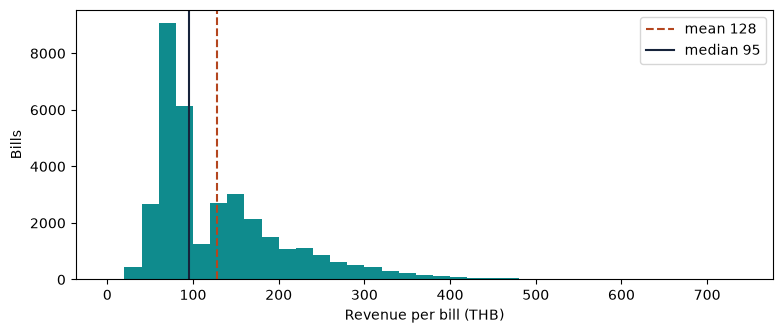

In [8]:
# ยอดต่อบิล: 1 บิล = รวมทุกแถวของ order_id เดียวกัน
bill = (pd.to_numeric(clean["qty"]) * pd.to_numeric(clean["unit_price"])).groupby(clean["order_id"]).sum()
print(f"ค่าเฉลี่ยต่อบิล  ฿{bill.mean():,.2f}")
print(f"ค่ากลางต่อบิล   ฿{bill.median():,.2f}")
print(f"90% ของบิลไม่เกิน ฿{bill.quantile(0.9):,.0f}")

import matplotlib.pyplot as plt
ax = bill.plot.hist(bins=range(0, 760, 20), color="#0F8B8D", figsize=(9, 3.5))
ax.axvline(bill.mean(), color="#B4461F", linestyle="--", label=f"mean {bill.mean():.0f}")
ax.axvline(bill.median(), color="#16233B", label=f"median {bill.median():.0f}")
ax.set_xlabel("Revenue per bill (THB)"); ax.set_ylabel("Bills"); ax.legend()
plt.show()
# หมายเหตุ: ใช้ป้ายภาษาอังกฤษ เพราะ matplotlib ใน Colab ไม่มีฟอนต์ไทย จะแสดงเป็นกล่องสี่เหลี่ยม

**คำถามชวนคิด:** ถ้าจะตั้งโปรฯ “ซื้อครบ X บาท รับส่วนลด” ควรใช้ค่าเฉลี่ยหรือค่ากลางเป็นฐาน และ X ควรเป็นเท่าไร


---
### 🚀 เสร็จเร็ว? ลองต่อ
- ให้ AI เขียนฟังก์ชัน `clean_sales(path)` ที่รวมทุกขั้น เรียกครั้งเดียวได้ไฟล์สะอาด (จะใช้ต่อในคาบ 7 ตอนทำ pipeline อัตโนมัติ)
- เพิ่มคอลัมน์ `date` และ `hour` ลงในข้อมูลสะอาด แล้วตรวจว่าไม่มีวันที่เลื่อนเพราะ timezone
- ลองอ่าน `customers.csv` แล้วทำ profiling ด้วย prompt เดิม มีปัญหาอะไรไหม

### 🚀 ลองต่อ · Profiling `customers.csv`
ใช้ prompt profiling กับไฟล์ลูกค้า: ค่าว่าง ช่องว่างหัว/ท้าย รูปร่างของค่า รูปแบบ ค่าหมวดหมู่ แถวซ้ำ เบอร์ซ้ำ และ `joined_date`

อัปโหลด `customers.csv` ไว้โฟลเดอร์เดียวกับ notebook ก่อนรัน

In [9]:
# ===== Data profiling ของ cust (รายงานอย่างเดียว ไม่แก้ข้อมูล) =====
import re

cust = load_csv("customers.csv")
print(f"{len(cust):,} แถว × {cust.shape[1]} คอลัมน์")

def section(title):
    print(f"\n{'=' * 10} {title} {'=' * 10}")

def shape(v):
    """แทนตัวเลขด้วย 9 และตัวอังกฤษด้วย a เพื่อดูรูปแบบของค่า"""
    return re.sub(r"[A-Za-z]", "a", re.sub(r"\d", "9", v))

# 1) ค่าว่าง ช่องว่างหัว/ท้าย ค่าไม่ซ้ำ
section("1) ค่าว่าง / ช่องว่างหัว-ท้าย / ค่าไม่ซ้ำ")
print(pd.DataFrame({
    "ค่าว่าง": (cust.apply(lambda s: s.str.strip()) == "").sum(),
    "มีช่องว่างหัว/ท้าย": (cust != cust.apply(lambda s: s.str.strip())).sum(),
    "ค่าไม่ซ้ำ": cust.nunique(),
}))

# 2) รูปร่างของค่า
section("2) รูปร่างของค่า (9 = ตัวเลข, a = ตัวอังกฤษ)")
for col in ["customer_id", "home_branch_id", "joined_date", "phone"]:
    shapes = cust[col].map(shape).value_counts()
    print(f"{col}: " + ", ".join(f"{s!r} × {n:,}" for s, n in shapes.head(5).items())
          + (f" … อีก {len(shapes) - 5} แบบ" if len(shapes) > 5 else ""))

# 3) ตรวจรูปแบบ
section("3) ตรวจรูปแบบ")
RULES = {
    "customer_id": r"^C\d{5}$",
    "home_branch_id": r"^B0[1-5]$",
    "joined_date": r"^\d{4}-\d\d-\d\d$",
    "phone": r"^0\d\d-xxx-\d{4}$",
}
bad_format = {}
for col, pat in RULES.items():
    bad = ~cust[col].str.match(pat)
    bad_format[col] = int(bad.sum())
    example = cust.loc[bad, col].head(5).tolist()
    print(f"{col:<15} ผิดรูปแบบ {bad.sum():>5,}" + (f"  ตัวอย่าง {example}" if example else ""))

# 4) ค่าหมวดหมู่
section("4) ค่าหมวดหมู่")
for col in ["gender", "age_group", "home_branch_id"]:
    print(f"{col}:")
    for v, n in cust[col].value_counts().sort_index().items():
        print(f"   {v!r:<14} {n:>6,}")

# 5) แถวซ้ำ
section("5) แถวซ้ำ")
n_dup = int(cust.duplicated().sum())
n_id_dup = int(cust["customer_id"].duplicated().sum())
phone_dup = cust[cust["phone"].duplicated(keep=False)].sort_values(["phone", "customer_id"])
print(f"แถวซ้ำทุกคอลัมน์: {n_dup:,} · customer_id ซ้ำ: {n_id_dup:,}")
print(f"phone ซ้ำ: {phone_dup['phone'].nunique():,} เบอร์ ({len(phone_dup):,} แถว)")

# คนเดียวกันจริงไหม: ถ้าเป็นคนเดียวกัน ชื่อเล่น เพศ และกลุ่มอายุควรตรงกันทั้งกลุ่ม
same_person = phone_dup.groupby("phone")[["nickname", "gender", "age_group"]].nunique().eq(1).all(axis=1)
print(f"  ชื่อเล่น+เพศ+อายุ ตรงกันทั้งกลุ่ม: {int(same_person.sum()):,} เบอร์ · ไม่ตรง: {int((~same_person).sum()):,} เบอร์")
print(phone_dup.head(6).to_string(index=False))
# เบอร์ถูกปิดตรงกลาง เหลือ prefix 08X/09X/06X × เลขท้าย 4 หลัก → โอกาสชนกันโดยบังเอิญ
n_space = cust["phone"].str[:3].nunique() * 10_000
expected = len(cust) ** 2 / (2 * n_space)
print(f"  คาดว่าจะชนกันโดยบังเอิญราว {expected:.0f} คู่ (จากเบอร์ที่แยกได้ {n_space:,} แบบ)")

# 6) joined_date
section("6) joined_date")
jd = pd.to_datetime(cust["joined_date"], format="%Y-%m-%d", errors="coerce")
n_bad_date = int(jd.isna().sum() - bad_format["joined_date"])
print(f"รูปแบบถูกแต่เป็นวันที่ไม่มีจริง: {n_bad_date:,}")
print(f"ช่วงวันที่: {jd.min().date()} → {jd.max().date()}")
print(f"สัดส่วนวันที่ ≤ 12: {(jd.dt.day <= 12).mean():.1%} (ถ้าไม่สลับวัน/เดือน ควรใกล้ 12/30.4 ≈ 39%)")
print("จำนวนสมัครรายเดือน:")
monthly = jd.dt.to_period("M").value_counts().sort_index()
print(monthly.to_frame("สมัคร").T.to_string())

3,000 แถว × 7 คอลัมน์

========== 1) ค่าว่าง / ช่องว่างหัว-ท้าย / ค่าไม่ซ้ำ ==========
                ค่าว่าง  มีช่องว่างหัว/ท้าย  ค่าไม่ซ้ำ
customer_id           0                   0       3000
nickname              0                   0         24
gender                0                   0          3
age_group             0                   0          6
home_branch_id        0                   0          5
joined_date           0                   0        530
phone                 0                   0       2950

========== 2) รูปร่างของค่า (9 = ตัวเลข, a = ตัวอังกฤษ) ==========
customer_id: 'a99999' × 3,000
home_branch_id: 'a99' × 3,000
joined_date: '9999-99-99' × 3,000
phone: '999-aaa-9999' × 3,000

========== 3) ตรวจรูปแบบ ==========
customer_id     ผิดรูปแบบ     0
home_branch_id  ผิดรูปแบบ     0
joined_date     ผิดรูปแบบ     0
phone           ผิดรูปแบบ     0

========== 4) ค่าหมวดหมู่ ==========
gender:
   'ชาย'           1,232
   'หญิง'          1,652
   'ไม่ระบุ'        

In [10]:
for col in ["gender", "age_group", "home_branch_id", "nickname"]:
    vc = cust[col].value_counts()
    print(f"{col} ({len(vc)} ค่า):", {repr(k): v for k, v in vc.items()})

section("age_group เรียงตามช่วงอายุ")
AGE_ORDER = ["ต่ำกว่า 18", "18-24", "25-34", "35-44", "45-54", "55+"]
age = cust["age_group"].value_counts().reindex(AGE_ORDER)
print(pd.DataFrame({"คน": age, "สัดส่วน": (age / len(cust)).map("{:.1%}".format)}))
print("ค่าที่ไม่อยู่ในรายการ:", sorted(set(cust["age_group"]) - set(AGE_ORDER)) or "ไม่มี")

gender (3 ค่า): {"'หญิง'": 1652, "'ชาย'": 1232, "'ไม่ระบุ'": 116}
age_group (6 ค่า): {"'25-34'": 993, "'18-24'": 775, "'35-44'": 577, "'45-54'": 346, "'55+'": 196, "'ต่ำกว่า 18'": 113}
home_branch_id (5 ค่า): {"'B01'": 776, "'B05'": 693, "'B02'": 643, "'B04'": 483, "'B03'": 405}
nickname (24 ค่า): {"'อัญชลี'": 148, "'รัตนา'": 140, "'กมล'": 138, "'ปิยะ'": 137, "'ชนา'": 137, "'ธีร'": 133, "'จิรา'": 131, "'ธนา'": 131, "'นภัส'": 128, "'สุดา'": 127, "'พิม'": 126, "'กิตติ'": 124, "'ภัทร'": 124, "'ภูมิ'": 123, "'ทิพย์'": 123, "'ปวีณ'": 123, "'มานพ'": 122, "'ศิริ'": 121, "'อรุณ'": 119, "'สมชาย'": 116, "'ณัฐ'": 115, "'เกศ'": 109, "'วีระ'": 104, "'วรรณ'": 101}

========== age_group เรียงตามช่วงอายุ ==========
             คน สัดส่วน
age_group              
ต่ำกว่า 18  113    3.8%
18-24       775   25.8%
25-34       993   33.1%
35-44       577   19.2%
45-54       346   11.5%
55+         196    6.5%
ค่าที่ไม่อยู่ในรายการ: ไม่มี


### 🚀 ลองต่อ · เทียบค่าว่าง ช่องว่าง และค่าไม่ซ้ำ ของ 3 ไฟล์
เทียบ `customers`, `sales_raw` และ `sales_clean` ในตารางเดียว แล้วเทียบจำนวนค่าไม่ซ้ำกับจำนวนที่ควรมีตามหลักธุรกิจ

ถ้า `sales_raw` มีค่าไม่ซ้ำ **มากกว่า** ที่ควรมี ค่าที่เกินมาคือค่าสกปรกที่ต้องแก้ (ต้องรันเซลล์ขั้นที่ 4 และเซลล์ `customers.csv` ก่อน)

In [11]:
# ===== เทียบค่าว่าง / ช่องว่างหัว-ท้าย / ค่าไม่ซ้ำ ของ 3 ไฟล์ =====
# ใช้ df (sales_raw), clean (หลังทำความสะอาด) และ cust (customers) จากเซลล์ก่อนหน้า
def basic_profile(d):
    stripped = d.apply(lambda s: s.str.strip())
    return pd.DataFrame({
        "ค่าว่าง": (stripped == "").sum(),
        "ช่องว่าง": (d != stripped).sum(),
        "ค่าไม่ซ้ำ": d.nunique(),
    })

files = {"customers": cust, "sales_raw": df, "sales_clean": clean}
compare = pd.concat({name: basic_profile(d) for name, d in files.items()}, axis=1)
compare = compare.reindex(list(cust.columns) + [c for c in df.columns if c not in cust.columns])
print("จำนวนแถว: " + " · ".join(f"{name} {len(d):,}" for name, d in files.items()))
display(compare.astype("Int64"))

# ค่าไม่ซ้ำที่ควรมีตามหลักธุรกิจ เทียบกับที่เจอจริง
EXPECTED = {
    "branch": (len(STD_BRANCHES), "5 สาขามาตรฐาน"),
    "product_id": (40, "เมนู P001–P040"),
    "qty": (3, "1–3 ชิ้น"),
    "payment_method": (5, "5 วิธีจ่าย"),
    "channel": (2, "หน้าร้าน / เดลิเวอรี"),
}
rows = []
for col, (n_expected, meaning) in EXPECTED.items():
    extra = sorted(set(df[col]) - set(clean[col]))
    rows.append({
        "คอลัมน์": col, "ควรมี": n_expected, "ความหมาย": meaning,
        "sales_raw": df[col].nunique(), "sales_clean": clean[col].nunique(),
        "ค่าที่เกินมาใน raw": ", ".join(repr(v) for v in extra[:6]) + (" …" if len(extra) > 6 else ""),
    })
expected_table = pd.DataFrame(rows)
expected_table["raw เกิน"] = expected_table["sales_raw"] > expected_table["ควรมี"]
expected_table["clean ตรง"] = expected_table["sales_clean"] == expected_table["ควรมี"]
display(expected_table)

n_members = clean.loc[clean["customer_id"] != "", "customer_id"].nunique()
print(f"customer_id: ค่าไม่ซ้ำ {clean['customer_id'].nunique():,} รวมค่าว่าง '' → สมาชิกจริง {n_members:,} คน")
if compare[("sales_raw", "ช่องว่าง")].sum() == 0:
    print("หมายเหตุ: sales_raw ไม่มีช่องว่างหัว/ท้าย ถ้าไฟล์ผ่าน Excel มา ช่องว่างท้ายชื่อสาขาอาจหายไปตอนบันทึกเป็น xlsx")

จำนวนแถว: customers 3,000 · sales_raw 53,357 · sales_clean 53,057


customers                    sales_raw                    sales_clean                   
                 ค่าว่าง ช่องว่าง ค่าไม่ซ้ำ   ค่าว่าง ช่องว่าง ค่าไม่ซ้ำ     ค่าว่าง ช่องว่าง ค่าไม่ซ้ำ
customer_id            0        0      3000     28652        0      2508       28494        0      2508
nickname               0        0        24      <NA>     <NA>      <NA>        <NA>     <NA>      <NA>
gender                 0        0         3      <NA>     <NA>      <NA>        <NA>     <NA>      <NA>
age_group              0        0         6      <NA>     <NA>      <NA>        <NA>     <NA>      <NA>
home_branch_id         0        0         5      <NA>     <NA>      <NA>        <NA>     <NA>      <NA>
joined_date            0        0       530      <NA>     <NA>      <NA>        <NA>     <NA>      <NA>
phone                  0        0      2950      <NA>     <NA>      <NA>        <NA>     <NA>      <NA>
order_id            <NA>     <NA>      <NA>         0        0     34791           0        0     34773
datetime            <NA>     <NA>      <NA>         0        0     35456           0        0     35045
branch              <NA>     <NA>      <NA>         0        0        13           0        0         5
product_id          <NA>     <NA>      <NA>        15        0        41           0        0        40
qty                 <NA>     <NA>      <NA>         0        0         4           0        0         3
unit_price          <NA>     <NA>      <NA>         0        0        49           0        0        26
payment_method      <NA>     <NA>      <NA>         0        0         5           0        0         5
channel             <NA>     <NA>      <NA>         0        0         2           0        0         2

,คอลัมน์,ควรมี,ความหมาย,sales_raw,sales_clean,ค่าที่เกินมาใน raw,raw เกิน,clean ตรง
0,branch,5,5 สาขามาตรฐาน,13,5,"'Ari', 'Bangna', 'Siam', 'Silom', 'ม.', 'มหาลั...",True,True
1,product_id,40,เมนู P001–P040,41,40,'',True,True
2,qty,3,1–3 ชิ้น,4,3,'0',True,True
3,payment_method,5,5 วิธีจ่าย,5,5,,False,True
4,channel,2,หน้าร้าน / เดลิเวอรี,2,2,,False,True


customer_id: ค่าไม่ซ้ำ 2,508 รวมค่าว่าง '' → สมาชิกจริง 2,507 คน
หมายเหตุ: sales_raw ไม่มีช่องว่างหัว/ท้าย ถ้าไฟล์ผ่าน Excel มา ช่องว่างท้ายชื่อสาขาอาจหายไปตอนบันทึกเป็น xlsx


### 2.2 รูปแบบของค่าในแต่ละคอลัมน์
แทนตัวเลขด้วย `9` ตัวอังกฤษด้วย `a` และตัวอักษรไทยต่อกันด้วย `ก…` ถ้าคอลัมน์ไหนมีหลายรูปแบบ แปลว่ามีค่าที่หน้าตาไม่เหมือนเพื่อน

**หลายรูปแบบไม่ได้แปลว่าผิดเสมอ** เช่น `age_group` มี `99-99`, `99+` และ `ก… 99` ซึ่งถูกทั้งหมด ต้องดูตัวอย่างแล้วตัดสินเอง และวิธีนี้จับได้เฉพาะค่าที่หน้าตาต่าง ปี พ.ศ. แบบ `2568-04-01T…` มีรูปแบบเหมือนปี ค.ศ. จึงต้องตรวจด้วยเงื่อนไขอื่นเพิ่ม

In [12]:
# ===== 2.2 รูปแบบของค่าในแต่ละคอลัมน์ =====
# ตัวอักษรไทยที่ต่อกัน → ก…  ·  ตัวเลข → 9  ·  ตัวอังกฤษ → a  (ช่องว่างและเครื่องหมายคงไว้)
import re

THAI_RUN = re.compile(r"[฀-๿]+")

def value_shape(v):
    if v == "":
        return "(ว่าง)"
    v = THAI_RUN.sub("ก…", v)
    v = re.sub(r"\d", "9", v)
    return re.sub(r"[A-Za-z]", "a", v)

def shape_report(d, name, top=4):
    print(f"\n{'=' * 10} {name} ({len(d):,} แถว) {'=' * 10}")
    summary = []
    for col in d.columns:
        shapes = d[col].map(value_shape)
        counts = shapes.value_counts()
        summary.append({"คอลัมน์": col, "จำนวนรูปแบบ": len(counts)})
        flag = "  ← มีหลายรูปแบบ" if len(counts) > 1 else ""
        print(f"{col} · {len(counts)} รูปแบบ{flag}")
        for s, n in counts.head(top).items():
            example = d.loc[shapes == s, col].iloc[0]
            print(f"   {s!r:<28} {n:>7,}  เช่น {example!r}")
        if len(counts) > top:
            print(f"   … อีก {len(counts) - top} รูปแบบ")
    return pd.DataFrame(summary).set_index("คอลัมน์")["จำนวนรูปแบบ"]

shape_counts = pd.concat({
    "customers": shape_report(cust, "customers"),
    "sales_raw": shape_report(df, "sales_raw"),
    "sales_clean": shape_report(clean, "sales_clean"),
}, axis=1)

print(f"\n{'=' * 10} สรุปจำนวนรูปแบบต่อคอลัมน์ {'=' * 10}")
display(shape_counts.astype("Int64"))


========== customers (3,000 แถว) ==========
customer_id · 1 รูปแบบ
   'a99999'                       3,000  เช่น 'C00001'
nickname · 1 รูปแบบ
   'ก…'                           3,000  เช่น 'กมล'
gender · 1 รูปแบบ
   'ก…'                           3,000  เช่น 'หญิง'
age_group · 3 รูปแบบ  ← มีหลายรูปแบบ
   '99-99'                        2,691  เช่น '18-24'
   '99+'                            196  เช่น '55+'
   'ก… 99'                          113  เช่น 'ต่ำกว่า 18'
home_branch_id · 1 รูปแบบ
   'a99'                          3,000  เช่น 'B02'
joined_date · 1 รูปแบบ
   '9999-99-99'                   3,000  เช่น '2026-03-03'
phone · 1 รูปแบบ
   '999-aaa-9999'                 3,000  เช่น '082-xxx-6693'

========== sales_raw (53,357 แถว) ==========


order_id · 1 รูปแบบ
   'aaa9999999'                  53,357  เช่น 'ORD0000001'


datetime · 2 รูปแบบ  ← มีหลายรูปแบบ
   '9999-99-99a99:99:99+99:99'   52,825  เช่น '2025-04-01T17:09:07+07:00'
   '99/99/9999 99:99'               532  เช่น '01/04/2025 10:54'
branch · 6 รูปแบบ  ← มีหลายรูปแบบ
   'ก…'                          52,865  เช่น 'สยาม'
   'aaaaa'                          122  เช่น 'Silom'
   'aaaaaa'                         111  เช่น 'Bangna'
   'aaaa'                           108  เช่น 'Siam'
   … อีก 2 รูปแบบ


product_id · 2 รูปแบบ  ← มีหลายรูปแบบ
   'a999'                        53,342  เช่น 'P015'
   '(ว่าง)'                          15  เช่น ''
qty · 1 รูปแบบ
   '9'                           53,357  เช่น '1'


unit_price · 6 รูปแบบ  ← มีหลายรูปแบบ
   '99'                          50,503  เช่น '60'
   '999'                          2,768  เช่น '105'
   '99.99 ก…'                        58  เช่น '55.00 บาท'
   '-99'                             23  เช่น '-85'
   … อีก 2 รูปแบบ
customer_id · 2 รูปแบบ  ← มีหลายรูปแบบ
   '(ว่าง)'                      28,652  เช่น ''
   'a99999'                      24,705  เช่น 'C00701'


...

datetime · 1 รูปแบบ
   '9999-99-99a99:99:99+99:99'   53,057  เช่น '2025-04-01T17:09:07+07:00'
branch · 1 รูปแบบ
   'ก…'                          53,057  เช่น 'สยาม'


product_id · 1 รูปแบบ
   'a999'                        53,057  เช่น 'P015'
qty · 1 รูปแบบ
   '9'                           53,057  เช่น '1'


unit_price · 2 รูปแบบ  ← มีหลายรูปแบบ
   '99'                          50,298  เช่น '60'
   '999'                          2,759  เช่น '105'
customer_id · 2 รูปแบบ  ← มีหลายรูปแบบ
   '(ว่าง)'                      28,494  เช่น ''
   'a99999'                      24,563  เช่น 'C00701'


payment_method · 4 รูปแบบ  ← มีหลายรูปแบบ
   'aa ก…'                       25,516  เช่น 'QR พร้อมเพย์'
   'ก…'                          16,984  เช่น 'บัตรเครดิต'
   'aaaa aaa'                     5,796  เช่น 'LINE MAN'
   'aaaa'                         4,761  เช่น 'Grab'
channel · 1 รูปแบบ
   'ก…'                          53,057  เช่น 'หน้าร้าน'

========== สรุปจำนวนรูปแบบต่อคอลัมน์ ==========


,customers,sales_raw,sales_clean
คอลัมน์,,,
customer_id,1,2,2
nickname,1,<NA>,<NA>
gender,1,<NA>,<NA>
age_group,3,<NA>,<NA>
home_branch_id,1,<NA>,<NA>
joined_date,1,<NA>,<NA>
phone,1,<NA>,<NA>
order_id,<NA>,1,1
datetime,<NA>,2,1


### 2.4 ค่าซ้ำ
ไฟล์ลูกค้า 1 แถว = 1 คน ดังนั้น `customer_id` ต้องไม่ซ้ำ ส่วน `phone` ถูกปิดเลขกลางไว้ (`xxx`) จึงต้องตรวจก่อนว่าเบอร์ที่ซ้ำเป็นคนเดียวกันจริงหรือไม่ โดยดูว่าชื่อเล่น เพศ และกลุ่มอายุตรงกันไหม และเทียบจำนวนคู่ที่ชนกันกับโอกาสชนกันโดยบังเอิญ

In [13]:
# ===== 2.4 ค่าซ้ำ =====
# 1 แถว = 1 คน → customer_id ต้องไม่ซ้ำ
n_row_dup = int(cust.duplicated().sum())
n_id_dup = int(cust["customer_id"].duplicated().sum())
print(f"แถวซ้ำทุกคอลัมน์: {n_row_dup:,}")
print(f"customer_id ซ้ำ: {n_id_dup:,}  {'✅ 1 แถว = 1 คน' if n_id_dup == 0 else '❌ มีลูกค้าซ้ำ'}")
if n_id_dup:
    print(cust[cust["customer_id"].duplicated(keep=False)].sort_values("customer_id").head(10).to_string(index=False))

# phone ถูกปิดเลขกลาง (xxx) → เบอร์ที่ซ้ำอาจเป็นคนละคนที่บังเอิญมีเลขนำหน้าและเลขท้ายตรงกัน
dup_phone = cust[cust["phone"].duplicated(keep=False)].sort_values(["phone", "customer_id"])
print(f"\nphone ซ้ำ: {dup_phone['phone'].nunique():,} เบอร์ ({len(dup_phone):,} แถว)")

# ถ้าเป็นคนเดียวกันจริง ข้อมูลส่วนตัวควรตรงกันทั้งกลุ่ม
PERSON_COLS = ["nickname", "gender", "age_group"]
per_phone = dup_phone.groupby("phone")[PERSON_COLS].nunique()
match = per_phone.eq(1)
print("คอลัมน์ที่ตรงกันทั้งกลุ่ม (นับเป็นเบอร์):")
for col in PERSON_COLS:
    print(f"   {col:<10} {int(match[col].sum()):>3,} / {len(per_phone):,}")
same_person = match.all(axis=1)
print(f"ข้อมูลตรงกันทุกคอลัมน์ (น่าจะเป็นคนเดียวกัน): {int(same_person.sum()):,} เบอร์")
if same_person.any():
    print(dup_phone[dup_phone["phone"].isin(same_person[same_person].index)].to_string(index=False))

# เทียบกับโอกาสชนกันโดยบังเอิญ: เบอร์ที่แยกได้ = จำนวนเลขนำหน้า × เลขท้าย 4 หลัก
n_space = cust["phone"].str[:3].nunique() * 10_000
expected_pairs = len(cust) * (len(cust) - 1) / (2 * n_space)
observed_pairs = int(cust.groupby("phone").size().map(lambda k: k * (k - 1) // 2).sum())
print(f"\nคู่ที่เบอร์ชนกัน: เจอ {observed_pairs:,} คู่ · คาดว่าชนโดยบังเอิญ {expected_pairs:.0f} คู่ (เบอร์ที่แยกได้ {n_space:,} แบบ)")

print("\nตัวอย่างเบอร์ซ้ำ:")
print(dup_phone.head(6).to_string(index=False))
verdict = ("เบอร์ซ้ำเกิดจากการปิดเลขกลาง ไม่ใช่คนเดียวกัน · ห้ามใช้ phone ลบลูกค้าซ้ำ"
           if not same_person.any() else "มีบางเบอร์ที่ข้อมูลตรงกันทุกคอลัมน์ ต้องตรวจต่อก่อนตัดสินว่าเป็นคนเดียวกัน")
print(f"\nสรุป: {verdict}")

แถวซ้ำทุกคอลัมน์: 0
customer_id ซ้ำ: 0  ✅ 1 แถว = 1 คน



phone ซ้ำ: 49 เบอร์ (99 แถว)
คอลัมน์ที่ตรงกันทั้งกลุ่ม (นับเป็นเบอร์):
   nickname     1 / 49
   gender      26 / 49
   age_group   19 / 49
ข้อมูลตรงกันทุกคอลัมน์ (น่าจะเป็นคนเดียวกัน): 0 เบอร์

คู่ที่เบอร์ชนกัน: เจอ 51 คู่ · คาดว่าชนโดยบังเอิญ 50 คู่ (เบอร์ที่แยกได้ 90,000 แบบ)

ตัวอย่างเบอร์ซ้ำ:
customer_id nickname gender age_group home_branch_id joined_date        phone
     C02207    ทิพย์    ชาย     35-44            B02  2025-04-14 081-xxx-4308
     C02248   อัญชลี    ชาย     35-44            B02  2026-03-15 081-xxx-4308
     C02179   อัญชลี   หญิง     25-34            B01  2025-06-24 081-xxx-5843
     C02843      ธีร   หญิง     25-34            B05  2026-05-20 081-xxx-5843
     C00884     ภัทร    ชาย     45-54            B01  2025-09-07 081-xxx-6451
     C01907     ศิริ   หญิง     25-34            B03  2026-03-31 081-xxx-6451

สรุป: เบอร์ซ้ำเกิดจากการปิดเลขกลาง ไม่ใช่คนเดียวกัน · ห้ามใช้ phone ลบลูกค้าซ้ำ


### 2.5 joined_date
ตรวจว่าวันที่สมัครเป็นรูปแบบ `YYYY-MM-DD` และเป็นวันที่มีจริง อยู่ในช่วงเดียวกับยอดขาย ไม่สมัครก่อนสาขาประจำเปิด ไม่ซื้อก่อนวันสมัคร และไม่มีร่องรอยการสลับวันกับเดือน แล้วดูจำนวนสมัครรายเดือนและตามวันในสัปดาห์

In [14]:
# ===== 2.5 joined_date =====
jd_text = cust["joined_date"]
jd = pd.to_datetime(jd_text, format="%Y-%m-%d", errors="coerce")

# 1) รูปแบบและวันที่ที่มีจริง
bad_format = ~jd_text.str.match(r"^20\d\d-\d\d-\d\d$")
not_real = jd.isna() & ~bad_format
print(f"ไม่ใช่ YYYY-MM-DD ปี ค.ศ.: {int(bad_format.sum()):,}" +
      (f"  เช่น {jd_text[bad_format].head(5).tolist()}" if bad_format.any() else ""))
print(f"รูปแบบถูกแต่ไม่มีวันนั้นจริง (เช่น 2025-02-30): {int(not_real.sum()):,}")

# 2) ช่วงวันที่ เทียบกับช่วงของยอดขาย
sales_start = pd.Timestamp(clean["datetime"].str[:10].min())
sales_end = pd.Timestamp(clean["datetime"].str[:10].max())
print(f"\nช่วงวันที่สมัคร: {jd.min().date()} → {jd.max().date()} ({jd.nunique():,} วันที่ไม่ซ้ำ)")
print(f"ช่วงของยอดขาย:  {sales_start.date()} → {sales_end.date()}")
print(f"สมัครหลังวันสุดท้ายของยอดขาย (อนาคต): {int((jd > sales_end).sum()):,}")
print(f"สมัครก่อนวันแรกของยอดขาย: {int((jd < sales_start).sum()):,}")

# 3) สมัครก่อนสาขาประจำเปิด (วันเปิดจาก branches.xlsx)
BRANCH_OPENED = {"B01": "2023-06-01", "B02": "2023-09-15", "B03": "2025-11-01",
                 "B04": "2024-03-01", "B05": "2024-06-01"}
opened = pd.to_datetime(cust["home_branch_id"].map(BRANCH_OPENED))
before_open = jd < opened
print(f"\nสมัครก่อนสาขาประจำเปิด: {int(before_open.sum()):,}")
print(cust.assign(opened=opened.dt.date).groupby("home_branch_id")
      .agg(สาขาเปิด=("opened", "first"), สมัครวันแรก=("joined_date", "min"), สมาชิก=("customer_id", "size"))
      .to_string())

# 4) ซื้อครั้งแรกก่อนวันสมัคร
first_buy = (clean[clean["customer_id"] != ""]
             .groupby("customer_id")["datetime"].min().str[:10])
joined = cust.set_index("customer_id")["joined_date"]
common = first_buy.index.intersection(joined.index)
bought_before = first_buy[common] < joined[common]
days_to_first = (pd.to_datetime(first_buy[common]) - pd.to_datetime(joined[common])).dt.days
print(f"\nซื้อครั้งแรกก่อนวันสมัคร: {int(bought_before.sum()):,} จาก {len(common):,} คนที่เคยซื้อ")
print(f"จำนวนวันจากสมัครถึงซื้อครั้งแรก: ค่ากลาง {days_to_first.median():.0f} วัน · "
      f"ซื้อวันที่สมัคร {int((days_to_first == 0).sum()):,} คน · ภายใน 7 วัน {int((days_to_first <= 7).sum()):,} คน")

# 5) การสลับวัน/เดือน: ถ้าไม่สลับ วันที่ ≤ 12 ควรมีราว 12/30.4 ≈ 39%
print(f"\nสัดส่วนวันที่ ≤ 12: {(jd.dt.day <= 12).mean():.1%} (ควรใกล้ 39%)")
print(f"วันที่ 13–31 มี {int((jd.dt.day > 12).sum()):,} แถว ถ้าวัน/เดือนถูกสลับ แถวเหล่านี้จะกลายเป็นเดือนที่ 13–31 ซึ่งไม่มีจริง")

# 6) จำนวนสมัครรายเดือนและวันในสัปดาห์
print("\nสมัครรายเดือน:")
print(jd.dt.to_period("M").value_counts().sort_index().to_frame("สมัคร").T.to_string())
last_month = jd.dt.to_period("M").max()
print(f"หมายเหตุ: เดือน {last_month} มีข้อมูลถึงวันที่ {jd.max().day} เท่านั้น")
WEEKDAYS = ["จันทร์", "อังคาร", "พุธ", "พฤหัสบดี", "ศุกร์", "เสาร์", "อาทิตย์"]
print("\nสมัครตามวันในสัปดาห์:")
print(jd.dt.dayofweek.value_counts().sort_index().rename(dict(enumerate(WEEKDAYS)))
      .to_frame("สมัคร").T.to_string())

ไม่ใช่ YYYY-MM-DD ปี ค.ศ.: 0
รูปแบบถูกแต่ไม่มีวันนั้นจริง (เช่น 2025-02-30): 0

ช่วงวันที่สมัคร: 2025-04-01 → 2026-09-14 (530 วันที่ไม่ซ้ำ)
ช่วงของยอดขาย:  2025-04-01 → 2026-09-20
สมัครหลังวันสุดท้ายของยอดขาย (อนาคต): 0
สมัครก่อนวันแรกของยอดขาย: 0

สมัครก่อนสาขาประจำเปิด: 0
                  สาขาเปิด สมัครวันแรก  สมาชิก
home_branch_id                                
B01             2023-06-01  2025-04-01     776
B02             2023-09-15  2025-04-01     643
B03             2025-11-01  2025-11-01     405
B04             2024-03-01  2025-04-03     483
B05             2024-06-01  2025-04-01     693



ซื้อครั้งแรกก่อนวันสมัคร: 0 จาก 2,507 คนที่เคยซื้อ
จำนวนวันจากสมัครถึงซื้อครั้งแรก: ค่ากลาง 17 วัน · ซื้อวันที่สมัคร 97 คน · ภายใน 7 วัน 715 คน

สัดส่วนวันที่ ≤ 12: 40.2% (ควรใกล้ 39%)
วันที่ 13–31 มี 1,794 แถว ถ้าวัน/เดือนถูกสลับ แถวเหล่านี้จะกลายเป็นเดือนที่ 13–31 ซึ่งไม่มีจริง

สมัครรายเดือน:
joined_date  2025-04  2025-05  2025-06  2025-07  2025-08  2025-09  2025-10  2025-11  2025-12  2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08  2026-09
สมัคร            138      140      142      142      144      148      145      175      197      190      161      189      201      200      182      210      215       81
หมายเหตุ: เดือน 2026-09 มีข้อมูลถึงวันที่ 14 เท่านั้น

สมัครตามวันในสัปดาห์:


joined_date  จันทร์  อังคาร  พุธ  พฤหัสบดี  ศุกร์  เสาร์  อาทิตย์
สมัคร           444     440  417       425    419    404      451


### 2.6 phone
ตรวจว่าเบอร์เป็นรูปแบบ `0XX-xxx-XXXX` ทุกแถว ไม่มีเบอร์เต็มหลุดมา (ความเป็นส่วนตัว) เลขนำหน้าเป็นเบอร์มือถือไทย และเลขท้าย 4 หลักกระจายตัวแบบเลขสุ่ม ไม่มีเลขที่พิมพ์ใส่มั่ว ๆ

In [15]:
# ===== 2.6 phone =====
phone = cust["phone"]

# 1) รูปแบบ: เบอร์มือถือไทย 0XX-xxx-XXXX ที่ปิดเลขกลางไว้
PHONE_RE = r"^0\d\d-xxx-\d{4}$"
bad = ~phone.str.match(PHONE_RE)
print(f"ผิดรูปแบบ 0XX-xxx-XXXX: {int(bad.sum()):,}" + (f"  เช่น {phone[bad].head(5).tolist()}" if bad.any() else ""))

# 2) ความเป็นส่วนตัว: ต้องไม่มีเบอร์เต็มหลุดมา ทั้งในคอลัมน์ phone และคอลัมน์อื่น
FULL_PHONE = r"0\d{2}-?\d{3}-?\d{4}"
leaked = {col: int(cust[col].str.contains(FULL_PHONE).sum()) for col in cust.columns}
print(f"เบอร์เต็มที่ไม่ได้ปิดเลขกลาง: {sum(leaked.values()):,}" +
      (f"  ในคอลัมน์ {[c for c, n in leaked.items() if n]}" if any(leaked.values()) else ""))
print(f"ปิดเลขกลางด้วย 'xxx' ทุกแถว: {phone.str[4:7].eq('xxx').all()}")

# 3) เลขนำหน้า: มือถือไทยขึ้นต้นด้วย 06, 08, 09
prefix = phone.str[:3]
print("\nเลขนำหน้า:")
print(prefix.value_counts().sort_index().to_frame("คน").T.to_string())
non_mobile = ~prefix.str.match(r"^0[689]")
print(f"ไม่ใช่เลขนำหน้ามือถือ (06/08/09): {int(non_mobile.sum()):,}")

# 4) เลขท้าย 4 หลัก: ถ้าเป็นเลขสุ่มจริง แต่ละหลักควรกระจายเท่า ๆ กัน (หลักละ ~10%)
last4 = phone.str[-4:]
digit_share = pd.DataFrame({f"หลักที่ {i + 1}": last4.str[i].value_counts(normalize=True).sort_index()
                            for i in range(4)}).mul(100).round(1)
print("\nสัดส่วนตัวเลขในเลขท้าย 4 หลัก (%):")
print(digit_share.T.to_string())
SUSPICIOUS = ["0000", "1111", "1234", "9999"]
print(f"เลขท้ายน่าสงสัย {SUSPICIOUS}: {int(last4.isin(SUSPICIOUS).sum()):,}")

# 5) ใช้ phone ทำอะไรได้บ้าง
n_space = prefix.nunique() * 10_000
print(f"\nค่าไม่ซ้ำ {phone.nunique():,} จาก {len(cust):,} แถว · เบอร์ที่แยกได้ {n_space:,} แบบ")
print("สรุป: phone ผ่านการปิดเลขกลางแล้ว ใช้ติดต่อลูกค้าหรือหาลูกค้าซ้ำไม่ได้ (ดู 2.4) · ใช้ customer_id เป็น key แทน")

ผิดรูปแบบ 0XX-xxx-XXXX: 0
เบอร์เต็มที่ไม่ได้ปิดเลขกลาง: 0
ปิดเลขกลางด้วย 'xxx' ทุกแถว: True

เลขนำหน้า:
phone  081  082  083  084  085  086  087  088  089
คน     322  330  352  308  350  341  338  335  324
ไม่ใช่เลขนำหน้ามือถือ (06/08/09): 0

สัดส่วนตัวเลขในเลขท้าย 4 หลัก (%):
phone         0     1     2     3     4     5     6     7     8     9
หลักที่ 1   NaN  12.0  10.4  11.1  11.5  10.1  11.4  11.7  10.8  10.9
หลักที่ 2  10.2  11.4  10.2   9.7   9.5   9.6   9.9   9.8   9.8   9.7
หลักที่ 3  10.0  11.3   9.5   9.4  10.3   9.0   9.5  10.4  10.0  10.7
หลักที่ 4   9.3   9.8   9.7   9.9   9.5  10.6  10.4  10.8  10.1  10.0
เลขท้ายน่าสงสัย ['0000', '1111', '1234', '9999']: 1

ค่าไม่ซ้ำ 2,950 จาก 3,000 แถว · เบอร์ที่แยกได้ 90,000 แบบ
สรุป: phone ผ่านการปิดเลขกลางแล้ว ใช้ติดต่อลูกค้าหรือหาลูกค้าซ้ำไม่ได้ (ดู 2.4) · ใช้ customer_id เป็น key แทน


### เทียบทะเบียนลูกค้ากับยอดขาย
เทียบ `cust` (ทะเบียนลูกค้า) กับ `sales` (ใช้ `clean` จากขั้นที่ 4 · 1 แถว = 1 รายการ · `customer_id` ว่าง = ลูกค้าทั่วไป)
- `customer_id` ในยอดขายที่ไม่มีในทะเบียน และสมาชิกที่ไม่เคยซื้อ แยกตามไตรมาสที่สมัคร
- สมาชิกที่ซื้อครั้งแรกก่อนวันสมัคร และระยะเวลาจากสมัครถึงซื้อครั้งแรก
- สาขาประจำ (`home_branch_id`) เทียบกับสาขาที่ซื้อครั้งแรกและสาขาที่ซื้อบ่อยที่สุด (map ชื่อสาขาเป็น B01–B05 ก่อน)
- สมาชิกอายุต่ำกว่า 18 ที่จ่ายด้วยบัตรเครดิต

รายงานอย่างเดียว ไม่แก้ข้อมูล

In [16]:
# ===== เทียบทะเบียนลูกค้า (cust) กับยอดขาย (sales) · รายงานอย่างเดียว =====
# sales: 1 แถว = 1 รายการ · customer_id ว่าง = ลูกค้าทั่วไป
sales = clean
BRANCH_ID = {"สยาม": "B01", "สีลม": "B02", "อารีย์": "B03", "บางนา": "B04", "มหาวิทยาลัย": "B05"}

members = sales[sales["customer_id"] != ""].assign(branch_id=lambda d: d["branch"].map(BRANCH_ID))
unmapped = members["branch_id"].isna()
if unmapped.any():
    raise ValueError(f"ชื่อสาขาที่ map เป็น B01–B05 ไม่ได้: {members.loc[unmapped, 'branch'].unique().tolist()}")
print(f"ยอดขาย {len(sales):,} รายการ · ของสมาชิก {len(members):,} รายการ ({len(members) / len(sales):.1%})")

# 1) customer_id ในยอดขายที่ไม่มีในทะเบียน / สมาชิกที่ไม่เคยซื้อ
section("1) customer_id ที่ไม่ตรงกัน")
reg_ids, sale_ids = set(cust["customer_id"]), set(members["customer_id"])
not_registered = sorted(sale_ids - reg_ids)
print(f"customer_id ในยอดขายที่ไม่มีในทะเบียน: {len(not_registered):,}" +
      (f"  เช่น {not_registered[:5]}" if not_registered else ""))

cq = cust.assign(quarter=pd.to_datetime(cust["joined_date"]).dt.to_period("Q").astype(str),
                 bought=cust["customer_id"].isin(sale_ids))
by_q = cq.groupby("quarter").agg(สมัคร=("customer_id", "size"), ไม่เคยซื้อ=("bought", lambda b: int((~b).sum())))
by_q["สัดส่วนไม่เคยซื้อ"] = (by_q["ไม่เคยซื้อ"] / by_q["สมัคร"]).map("{:.1%}".format)
print(f"สมาชิกที่ไม่เคยซื้อ: {int((~cq['bought']).sum()):,} จาก {len(cq):,} คน · แยกตามไตรมาสที่สมัคร:")
print(by_q.to_string())
print(f"หมายเหตุ: ยอดขายถึง {sales['datetime'].str[:10].max()} คนที่เพิ่งสมัครจึงมีเวลาซื้อน้อยกว่า")

# 2) ซื้อครั้งแรกก่อนวันสมัคร และระยะเวลาจากสมัครถึงซื้อครั้งแรก
section("2) สมัคร → ซื้อครั้งแรก")
first = (members.sort_values("datetime").groupby("customer_id")
         .agg(first_buy=("datetime", "first"), first_branch=("branch_id", "first")))
first["first_date"] = pd.to_datetime(first["first_buy"].str[:10])
joined = pd.to_datetime(cust.set_index("customer_id")["joined_date"])
first["days"] = (first["first_date"] - joined.reindex(first.index)).dt.days
before = first["days"] < 0
print(f"ซื้อครั้งแรกก่อนวันสมัคร: {int(before.sum()):,} จาก {len(first):,} คน")
if before.any():
    print(first[before].head().to_string())
d = first.loc[~before, "days"]
buckets = pd.cut(d, [-1, 0, 7, 30, 90, 10_000], labels=["วันเดียวกัน", "1–7 วัน", "8–30 วัน", "31–90 วัน", "> 90 วัน"])
print(f"ระยะเวลา: ค่ากลาง {d.median():.0f} วัน · ค่าเฉลี่ย {d.mean():.0f} วัน · 90% ไม่เกิน {d.quantile(0.9):.0f} วัน · สูงสุด {d.max():,} วัน")
print(buckets.value_counts().sort_index().to_frame("คน").T.to_string())

# 3) สาขาประจำ เทียบกับสาขาที่ซื้อครั้งแรกและสาขาที่ซื้อบ่อยที่สุด (นับเป็นบิล)
section("3) สาขาประจำ vs สาขาที่ซื้อ")
bills = members.drop_duplicates("order_id")
most = (bills.groupby(["customer_id", "branch_id"]).size().rename("n").reset_index()
        .sort_values(["customer_id", "n", "branch_id"], ascending=[True, False, True])
        .drop_duplicates("customer_id").set_index("customer_id")["branch_id"])
cmp_branch = pd.DataFrame({
    "home": cust.set_index("customer_id")["home_branch_id"],
    "first": first["first_branch"],
    "most": most,
}).dropna()
print(f"สมาชิกที่เคยซื้อ {len(cmp_branch):,} คน")
print(f"สาขาประจำ = สาขาที่ซื้อครั้งแรก:    {(cmp_branch['home'] == cmp_branch['first']).mean():.1%}")
print(f"สาขาประจำ = สาขาที่ซื้อบ่อยที่สุด:   {(cmp_branch['home'] == cmp_branch['most']).mean():.1%}")
print(f"ไม่ตรงทั้งสองแบบ:                 {int(((cmp_branch['home'] != cmp_branch['first']) & (cmp_branch['home'] != cmp_branch['most'])).sum()):,} คน")
print("\nสาขาประจำ (แถว) × สาขาที่ซื้อบ่อยที่สุด (คอลัมน์):")
print(pd.crosstab(cmp_branch["home"], cmp_branch["most"], margins=True, margins_name="รวม").to_string())
share_home = bills.merge(cust[["customer_id", "home_branch_id"]], on="customer_id")
print(f"\nบิลของสมาชิกที่ซื้อที่สาขาประจำ: {(share_home['branch_id'] == share_home['home_branch_id']).mean():.1%}")

# 4) สมาชิกอายุต่ำกว่า 18 ที่จ่ายด้วยบัตรเครดิต
section("4) อายุต่ำกว่า 18 จ่ายด้วยบัตรเครดิต")
under18 = set(cust.loc[cust["age_group"] == "ต่ำกว่า 18", "customer_id"])
u18_bills = bills[bills["customer_id"].isin(under18)]
card = u18_bills[u18_bills["payment_method"] == "บัตรเครดิต"]
print(f"สมาชิกอายุต่ำกว่า 18: {len(under18):,} คน · มีบิล {len(u18_bills):,} บิล")
print(f"จ่ายด้วยบัตรเครดิต: {len(card):,} บิล ({len(card) / max(len(u18_bills), 1):.1%}) จาก {card['customer_id'].nunique():,} คน")
print(f"เทียบสมาชิกทุกคน: บัตรเครดิต {(bills['payment_method'] == 'บัตรเครดิต').mean():.1%} ของบิล")
print("วิธีจ่ายของกลุ่มอายุต่ำกว่า 18 (% ของบิล):")
print(u18_bills["payment_method"].value_counts(normalize=True).mul(100).round(1).to_frame("%").T.to_string())
print(card[["order_id", "datetime", "branch", "customer_id", "payment_method"]].head(5).to_string(index=False))

ยอดขาย 53,057 รายการ · ของสมาชิก 24,563 รายการ (46.3%)

========== 1) customer_id ที่ไม่ตรงกัน ==========
customer_id ในยอดขายที่ไม่มีในทะเบียน: 0
สมาชิกที่ไม่เคยซื้อ: 493 จาก 3,000 คน · แยกตามไตรมาสที่สมัคร:
         สมัคร  ไม่เคยซื้อ สัดส่วนไม่เคยซื้อ
quarter                                     
2025Q2     420          23              5.5%
2025Q3     434          23              5.3%
2025Q4     517          36              7.0%
2026Q1     540          59             10.9%
2026Q2     583         102             17.5%
2026Q3     506         250             49.4%
หมายเหตุ: ยอดขายถึง 2026-09-20 คนที่เพิ่งสมัครจึงมีเวลาซื้อน้อยกว่า

========== 2) สมัคร → ซื้อครั้งแรก ==========
ซื้อครั้งแรกก่อนวันสมัคร: 0 จาก 2,507 คน
ระยะเวลา: ค่ากลาง 17 วัน · ค่าเฉลี่ย 27 วัน · 90% ไม่เกิน 63 วัน · สูงสุด 411 วัน
days  วันเดียวกัน  1–7 วัน  8–30 วัน  31–90 วัน  > 90 วัน
คน             97      618      1062        614       116

========== 3) สาขาประจำ vs สาขาที่ซื้อ ==========
สมาชิกที่เคยซื้อ 2,507 คน



บิลของสมาชิกที่ซื้อที่สาขาประจำ: 88.4%

========== 4) อายุต่ำกว่า 18 จ่ายด้วยบัตรเครดิต ==========
สมาชิกอายุต่ำกว่า 18: 113 คน · มีบิล 726 บิล
จ่ายด้วยบัตรเครดิต: 104 บิล (14.3%) จาก 53 คน
เทียบสมาชิกทุกคน: บัตรเครดิต 14.5% ของบิล
วิธีจ่ายของกลุ่มอายุต่ำกว่า 18 (% ของบิล):
payment_method  QR พร้อมเพย์  เงินสด  บัตรเครดิต  LINE MAN  Grab
%                       45.3    20.5        14.3      11.2   8.7
  order_id                  datetime branch customer_id payment_method
ORD0002403 2025-05-14T09:03:17+07:00   สีลม      C01500     บัตรเครดิต
ORD0004618 2025-06-28T17:33:40+07:00   สยาม      C02477     บัตรเครดิต
ORD0005052 2025-07-06T11:16:36+07:00  บางนา      C00636     บัตรเครดิต
ORD0005252 2025-07-10T10:58:30+07:00  บางนา      C00636     บัตรเครดิต
ORD0005289 2025-07-11T11:31:04+07:00  บางนา      C00636     บัตรเครดิต
